# Continual-learning PDE baseline experiments

> **QUICK RUN SETTINGS:** The first code cell contains a highlighted 10-minute smoke-test block. Run that cell before running the launch cell.

This notebook runs the existing `train_cl.py` entry point over a configurable matrix of PDE streams, continual-learning algorithms, and random seeds. It then reads the metrics written to Aim and compares the final stream MSE and relative L2 error.

**Before running:** generate the datasets used by the selected streams and, for a strict pretrained comparison, set `CHECKPOINTS` below. The default values are intentionally small so the notebook can be smoke-tested; increase `EPOCHS` and select more seeds for a real experiment.

Run notebook cells from the repository root (or set `PDE_REPO_ROOT` explicitly). For Colab, use the isolated Python environment described below rather than downgrading protobuf in Colab's global environment.

In [1]:
from __future__ import annotations

import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

REPO_ROOT = Path(os.environ.get(
    "PDE_REPO_ROOT",
    "/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates",
)).expanduser().resolve()
if not (REPO_ROOT / "train_cl.py").exists():
    candidate = Path.cwd().resolve()
    while candidate != candidate.parent and not (candidate / "train_cl.py").exists():
        candidate = candidate.parent
    if (candidate / "train_cl.py").exists():
        REPO_ROOT = candidate
    else:
        raise FileNotFoundError(
            "Repository not found. Set PDE_REPO_ROOT to the directory containing train_cl.py."
        )
# Prefer the isolated Colab environment when it exists. Set PDE_PYTHON to
# override this path, or leave it unset when running locally in the project venv.
PDE_PYTHON = os.environ.get("PDE_PYTHON")
COLAB_PYTHON = Path("/content/pde-env/bin/python")
PYTHON = PDE_PYTHON or (str(COLAB_PYTHON) if COLAB_PYTHON.exists() else sys.executable)
# Aim 3.29.1 contains protobuf generated code that may need this compatibility
# implementation when the notebook kernel itself is running in Colab.
os.environ.setdefault("PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION", "python")
DATA_ROOT = REPO_ROOT / "data"
OUTPUTS_ROOT = REPO_ROOT / "outputs"
# =========== COMPACT CONTINUAL-LEARNING RUN (<20 MIN ON COLAB GPU) ==========
# This keeps all five DI experiences and all six algorithms, but uses one seed
# and one epoch. It is suitable for a first comparison, not a final paper run.
DEVICE = "cuda"  # Colab GPU; use "mps" locally on Apple Silicon.
NUM_WORKERS = 0

# DI mode contains five ordered physical-regime experiences.
STREAMS = {
    "advdiff1d_stream": {"model": "fno1d", "mode": "di"},
}

ALGORITHMS = ["naive", "replay", "replay_ts", "gem", "a_gem", "ewc"]
SEEDS = [123]
EPOCHS = 1
BATCH_SIZE = 1024
CONTEXT_LENGTH = 5
ROLLOUT_STEPS = 5
NUM_SNAPSHOTS_PER_SIM = 12
FNO_MODES = 8
FNO_WIDTH = 32
NUM_EMBS = {"fno1d": 2, "fno2d": 2}
LEARNING_RATE = 1e-4
STREAM_EXPERIMENT = "notebook_cl_compact_di_comparison"

# Optional pretrained weights by model. None starts from random initialization.
CHECKPOINTS = {"fno1d": None, "fno2d": None}

print(f"Repository: {REPO_ROOT}")
print(f"Training Python: {PYTHON}")
print(f"Planned runs: {len(STREAMS) * len(ALGORITHMS) * len(SEEDS)}")

Repository: /Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates
Planned runs: 6


## Launch the experiment matrix

A separate Hydra process is launched for each `(stream, algorithm)` pair. Seeds are passed as a Hydra multirun so each process can contain several repetitions. Algorithm-specific defaults match the repository's shell scripts.

In [2]:
def algorithm_overrides(algorithm: str) -> list[str]:
    """Return stable baseline overrides shared by the repository algorithms."""
    params = {
        "cl_algorithm.algorithm_parameters.epochs": EPOCHS,
        "cl_algorithm.algorithm_parameters.batch_size": BATCH_SIZE,
        "cl_algorithm.algorithm_parameters.optimizer_params.lr": LEARNING_RATE,
        "cl_algorithm.algorithm_parameters.num_workers": NUM_WORKERS,
    }
    if algorithm in {"replay", "replay_ts", "gem", "a_gem"}:
        params.update({
            "cl_algorithm.algorithm_parameters.memory_size": 200 if algorithm == "replay_ts" else 20,
            "cl_algorithm.algorithm_parameters.memory_mode": "experience_balanced",
        })
    if algorithm in {"replay", "replay_ts"}:
        params["cl_algorithm.algorithm_parameters.memory_seed"] = SEEDS[0]
    if algorithm == "replay":
        params.update({
            "cl_algorithm.algorithm_parameters.replay_batch_size": BATCH_SIZE,
            "cl_algorithm.algorithm_parameters.replay_loss_coef": 0.5,
        })
    elif algorithm == "replay_ts":
        params.update({
            "cl_algorithm.algorithm_parameters.replay_slice_factor": 10,
            "cl_algorithm.algorithm_parameters.replay_loss_coef": 5.0,
        })
    elif algorithm == "gem":
        params.update({
            "cl_algorithm.algorithm_parameters.memory_batch_size": 64,
            "cl_algorithm.algorithm_parameters.eps_gem": 1e-6,
            "cl_algorithm.algorithm_parameters.gamma": 0.9,
        })
    elif algorithm == "a_gem":
        params.update({
            "cl_algorithm.algorithm_parameters.memory_batch_size": 64,
            "cl_algorithm.algorithm_parameters.eps_agem": 1e-6,
        })
    elif algorithm == "ewc":
        params["cl_algorithm.algorithm_parameters.ewc_lambda"] = 30.0
    return [f"{key}={value}" for key, value in params.items()]


def build_command(stream_name: str, algorithm: str) -> list[str]:
    settings = STREAMS[stream_name]
    checkpoint = CHECKPOINTS[settings["model"]]
    overrides = [
        "--multirun",
        f"device={DEVICE}",
        f"logger.outputs_dir={OUTPUTS_ROOT}",
        f"logger.experiment={STREAM_EXPERIMENT}",
        f"model={settings['model']}",
        f"model.model_parameters.num_channels=1",
        f"model.model_parameters.modes={FNO_MODES}",
        f"model.model_parameters.width={FNO_WIDTH}",
        f"model.model_parameters.initial_step={CONTEXT_LENGTH}",
        f"model.model_parameters.num_embs={NUM_EMBS[settings['model']]}",
        f"cl_algorithm={algorithm}",
        f"stream={stream_name}",
        f"stream.dataset.dataset_params.dataset_root={DATA_ROOT / stream_name}",
        f"stream.stream_mode={settings['mode']}",
        f"stream.dataset.dataset_params.num_snapshots_per_sim={NUM_SNAPSHOTS_PER_SIM}",
        f"stream.dataset.dataset_params.rollout_steps={ROLLOUT_STEPS}",
        f"stream.dataset.dataset_params.context_length={CONTEXT_LENGTH}",
        "stream.dataset.dataset_params.aux_features=[exp_id]",
        f"stream.seed={','.join(map(str, SEEDS))}",
        f"seed={SEEDS[0]}",
    ] + algorithm_overrides(algorithm)
    if checkpoint:
        overrides.append(f"checkpoint_path={checkpoint}")
    return [PYTHON, "train_cl.py", *overrides]


def run_matrix(dry_run: bool = True) -> None:
    if not dry_run and DEVICE == "cuda":
        import torch
        if not torch.cuda.is_available():
            raise RuntimeError(
                "DEVICE='cuda' but Colab has no CUDA GPU. Enable Runtime > Change runtime type > GPU, "
                "or set DEVICE='cpu'."
            )
    for stream_name in STREAMS:
        for algorithm in ALGORITHMS:
            command = build_command(stream_name, algorithm)
            print("$", " ".join(map(str, command)))
            if not dry_run:
                completed = subprocess.run(
                    command,
                    cwd=REPO_ROOT,
                    text=True,
                    capture_output=True,
                )
                if completed.stdout:
                    print(completed.stdout, end="")
                if completed.stderr:
                    print(completed.stderr, end="", file=sys.stderr)
                if completed.returncode:
                    raise RuntimeError(
                        f"Experiment failed for stream={stream_name}, algorithm={algorithm} "
                        f"with exit code {completed.returncode}. See the subprocess output above."
                    )


run_matrix(dry_run=True)


$ /Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/.venv/bin/python train_cl.py --multirun device=mps logger.outputs_dir=/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/outputs logger.experiment=notebook_cl_all_algorithms_quick model=fno1d model.model_parameters.num_channels=1 model.model_parameters.modes=2 model.model_parameters.width=8 model.model_parameters.initial_step=3 model.model_parameters.num_embs=2 cl_algorithm=naive stream=advdiff1d_stream stream.dataset.dataset_params.dataset_root=/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/data/advdiff1d_stream stream.stream_mode=pretrain stream.dataset.dataset_params.rollout_steps=2 stream.dataset.dataset_params.context_length=3 stream.dataset.dataset_params.aux_features=[exp_id] stream.seed=123 seed=123 cl_algorithm.algorithm_parameters.epochs=1 cl_algorithm.algorithm_parameters.batch_size=512 cl_algorithm.algorithm_parameters.optimizer_par

In [3]:
# Set dry_run=False only after checking the printed commands and dataset paths.
run_matrix(dry_run=False)

$ /Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/.venv/bin/python train_cl.py --multirun device=mps logger.outputs_dir=/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/outputs logger.experiment=notebook_cl_all_algorithms_quick model=fno1d model.model_parameters.num_channels=1 model.model_parameters.modes=2 model.model_parameters.width=8 model.model_parameters.initial_step=3 model.model_parameters.num_embs=2 cl_algorithm=naive stream=advdiff1d_stream stream.dataset.dataset_params.dataset_root=/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/data/advdiff1d_stream stream.stream_mode=pretrain stream.dataset.dataset_params.rollout_steps=2 stream.dataset.dataset_params.context_length=3 stream.dataset.dataset_params.aux_features=[exp_id] stream.seed=123 seed=123 cl_algorithm.algorithm_parameters.epochs=1 cl_algorithm.algorithm_parameters.batch_size=512 cl_algorithm.algorithm_parameters.optimizer_par

Epoch 1/1: 100%|██████████| 167/167 [01:11<00:00,  2.34it/s]
/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)


Evaluating on stream
$ /Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/.venv/bin/python train_cl.py --multirun device=mps logger.outputs_dir=/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/outputs logger.experiment=notebook_cl_all_algorithms_quick model=fno1d model.model_parameters.num_channels=1 model.model_parameters.modes=2 model.model_parameters.width=8 model.model_parameters.initial_step=3 model.model_parameters.num_embs=2 cl_algorithm=replay stream=advdiff1d_stream stream.dataset.dataset_params.dataset_root=/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/data/advdiff1d_stream stream.stream_mode=pretrain stream.dataset.dataset_params.rollout_steps=2 stream.dataset.dataset_params.context_length=3 stream.dataset.dataset_params.aux_features=[exp_id] stream.seed=123 seed=123 cl_algorithm.algorithm_parameters.epochs=1 cl_algorithm.algorithm_parameters.batch_size=512 cl_algorithm.algorithm_pa

Epoch 1/1: 100%|██████████| 167/167 [01:10<00:00,  2.39it/s]


Evaluating on stream


...

Evaluating on stream


/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)


$ /Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/.venv/bin/python train_cl.py --multirun device=mps logger.outputs_dir=/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/outputs logger.experiment=notebook_cl_all_algorithms_quick model=fno1d model.model_parameters.num_channels=1 model.model_parameters.modes=2 model.model_parameters.width=8 model.model_parameters.initial_step=3 model.model_parameters.num_embs=2 cl_algorithm=ewc stream=advdiff1d_stream stream.dataset.dataset_params.dataset_root=/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/data/advdiff1d_stream stream.stream_mode=pretrain stream.dataset.dataset_params.rollout_steps=2 stream.dataset.dataset_params.context_length=3 stream.dataset.dataset_params.aux_features=[exp_id] stream.seed=123 seed=123 cl_algorithm.algorithm_parameters.epochs=1 cl_algorithm.algorithm_parameters.batch_size=512 cl_algorithm.algorithm_parameters.optimizer_param

Epoch 1/1: 100%|██████████| 167/167 [01:11<00:00,  2.34it/s]
/Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)


Evaluating on stream


## Collect and compare results

The trainer logs `test_loss_stream` and `test_loss_rell2_stream` to Aim after every experience. The collector selects the final value for each run and preserves the stream, algorithm, seed, and run hash in a tidy table.

In [ ]:
from aim import Run


def _latest_metric(run: Run, metric_name: str) -> float | None:
    """Read the last value of a named Aim metric.

    Aim's BasicRun.metrics() does not accept a query keyword, so filter
    its dataframe instead of relying on a version-specific API.
    """
    metrics = run.metrics().dataframe()
    matching = metrics[metrics["metric.name"] == metric_name]
    if matching.empty:
        return None
    return float(matching.sort_values("step").iloc[-1]["value"])


def collect_results() -> pd.DataFrame:
    rows = []
    runs_root = OUTPUTS_ROOT / "runs"
    if not runs_root.exists():
        raise FileNotFoundError(f"No runs found at {runs_root}. Run the matrix first.")
    for config_path in runs_root.glob("*/config.yaml"):
        with config_path.open() as file:
            config = yaml.safe_load(file)
        if config.get("logger", {}).get("experiment") != STREAM_EXPERIMENT:
            continue
        run_hash = config_path.parent.name
        run = Run(run_hash, repo=str(OUTPUTS_ROOT / ".aim"))
        rows.append({
            "run_hash": run_hash,
            "stream": config["stream"]["stream_name"],
            "algorithm": config["cl_algorithm"]["algorithm_name"],
            "seed": config["seed"],
            "test_mse": _latest_metric(run, "test_loss_stream"),
            "test_relative_l2": _latest_metric(run, "test_loss_rell2_stream"),
        })
    result = pd.DataFrame(rows)
    if result.empty:
        raise RuntimeError(f"No Aim runs found for experiment {STREAM_EXPERIMENT!r}")
    return result.sort_values(["stream", "algorithm", "seed"]).reset_index(drop=True)


results = collect_results()
display(results)


,run_hash,stream,algorithm,seed,test_mse,test_relative_l2
0,62b264c0b3eb489fa796ac3b,advdiff1d_stream,a_gem,123,0.190158,0.556180
1,9a799e98836443c5a16ed851,advdiff1d_stream,ewc,123,0.190167,0.556192
2,663b6479cafd4150aa625d5a,advdiff1d_stream,gem,123,0.190167,0.556192
3,a6356c1b9edb4863bd252349,advdiff1d_stream,naive,123,0.190167,0.556192
4,e9116416b70846ef8029a4db,advdiff1d_stream,naive,123,0.190167,0.556192
5,5bf567a1f1564cccaa8dc166,advdiff1d_stream,replay,123,0.190167,0.556192
6,15f6372e95db429fa0b2bb16,advdiff1d_stream,replay,123,0.190167,0.556192
7,bb105de55d254dbaa24e6186,advdiff1d_stream,replay_ts,123,0.190167,0.556192
8,937d1a39d5dd453a83b94fdd,advdiff1d_stream,replay_ts,123,0.190167,0.556192


,stream,algorithm,test_mse_mean,test_mse_std,test_relative_l2_mean,test_relative_l2_std,repetitions
0,advdiff1d_stream,a_gem,0.190158,NaN,0.556180,NaN,1
1,advdiff1d_stream,ewc,0.190167,NaN,0.556192,NaN,1
2,advdiff1d_stream,gem,0.190167,NaN,0.556192,NaN,1
3,advdiff1d_stream,naive,0.190167,0.0,0.556192,0.0,2
4,advdiff1d_stream,replay,0.190167,0.0,0.556192,0.0,2
5,advdiff1d_stream,replay_ts,0.190167,0.0,0.556192,0.0,2


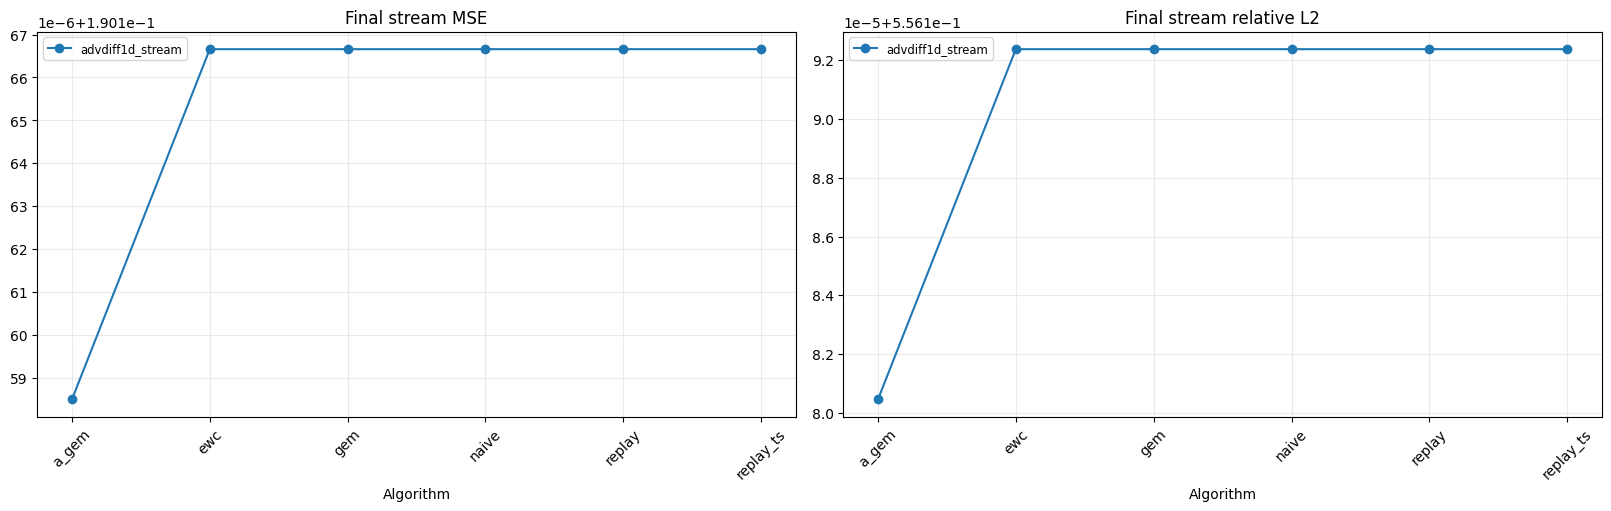

Saved /Users/balajiram/Downloads/continual_learning_for_autoregressive_pde_surrogates/outputs/notebook_cl_all_algorithms_quick_summary.csv


In [5]:
summary = (
        results.groupby(["stream", "algorithm"], as_index=False)
        .agg(
            test_mse_mean=("test_mse", "mean"),
            test_mse_std=("test_mse", "std"),
            test_relative_l2_mean=("test_relative_l2", "mean"),
            test_relative_l2_std=("test_relative_l2", "std"),
            repetitions=("seed", "count"),
        )
    )
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
for stream, group in summary.groupby("stream"):
    axes[0].plot(group["algorithm"], group["test_mse_mean"], marker="o", label=stream)
    axes[1].plot(group["algorithm"], group["test_relative_l2_mean"], marker="o", label=stream)
axes[0].set_title("Final stream MSE")
axes[1].set_title("Final stream relative L2")
for ax in axes:
    ax.set_xlabel("Algorithm")
    ax.grid(alpha=0.25)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize="small")
plt.show()

summary.to_csv(OUTPUTS_ROOT / f"{STREAM_EXPERIMENT}_summary.csv", index=False)
print(f"Saved {OUTPUTS_ROOT / f'{STREAM_EXPERIMENT}_summary.csv'}")